# 09 — GNN Training

Train the first **GINE molecular neural network** for aqueous-solubility regression on TDC **Solubility_AqSolDB**.

This notebook follows the existing experimental protocol in `04_model_training.ipynb`:

- Read the **raw molecular graphs** generated by `08_gnn_graph_generation.ipynb`; do not rebuild conformers or G6 features.
- Reproduce the official TDC train/validation split through `get_train_valid_split(..., split_type="default", seed=...)`.
- Fit `GraphFeatureNormalizer` **only on the training fold** for each seed.
- Train `MolecularGNN` with AdamW, Huber loss, gradient clipping, and early stopping on **validation MAE**.
- Store the best checkpoint, its normalizer, learning curves, and validation predictions.

**Test-set isolation:** the official TDC `test` partition is **not loaded or evaluated here**. The final test evaluation belongs in the subsequent notebook, after model selection.

**Execution modes:** `SMOKE_TEST=True` runs two epochs on a small subset to check the whole pipeline, and stores results under `smoke/`. Change to `False` for real experiments; those results are stored under `full/`.

## 1. Environment and imports

Run from the repository root or the `notebooks/` directory. On Windows, use the Jupyter kernel where both PyTorch and PyTorch Geometric are installed. `num_workers=0` is the recommended starting point for notebooks on Windows.

In [2]:
from pathlib import Path
from dataclasses import asdict
import json
import random
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from torch_geometric.loader import DataLoader
from tdc.benchmark_group import admet_group

CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.gnn.config import GNNConfig
from src.gnn.graph_builder import get_graph_feature_names
from src.gnn.normalizer import GraphFeatureNormalizer
from src.models.gnn import MolecularGNN

RAW_DIR = PROJECT_ROOT / "data" / "raw"
GRAPH_DIR = PROJECT_ROOT / "data" / "processed" / "aqsoldb" / "gnn"
BENCHMARK_NAME = "Solubility_AqSolDB"

print("Project root:", PROJECT_ROOT)
print("PyTorch:", torch.__version__)
print("Device available:", "CUDA" if torch.cuda.is_available() else "CPU")

Project root: C:\Users\alexc\OneDrive\Desktop\proyectos\admet-ml
PyTorch: 2.15.0+cpu
Device available: CPU


## 2. Experiment configuration

The architecture and optimization parameters come from `GNNConfig`. By default we start with **one seed** and a two-epoch smoke test. For the real scaffold-split study, use `SMOKE_TEST = False` and `SEEDS = [0, 1, 2, 3, 4]`, consistent with the earlier XGBoost experiments.

In [ ]:
config = GNNConfig()

SEEDS = [0, 1, 2, 3, 4]
SMOKE_TEST = False  # Change to False for full training.
SMOKE_TRAIN_SIZE = 64
SMOKE_VALID_SIZE = 32
SMOKE_EPOCHS = 2

RUN_MODE = "smoke" if SMOKE_TEST else "full"
MODEL_DIR = PROJECT_ROOT / "data" /"models" / "gnn" / RUN_MODE
RESULTS_DIR = PROJECT_ROOT / "data" / "results" / "gnn" / RUN_MODE
MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

requested_device = config.training.device
DEVICE = torch.device(
    ("cuda" if torch.cuda.is_available() else "cpu")
    if requested_device == "auto" else requested_device
)

MAX_EPOCHS = SMOKE_EPOCHS if SMOKE_TEST else config.training.max_epochs
BATCH_SIZE = min(config.training.batch_size, 16) if SMOKE_TEST else config.training.batch_size

print("Mode:", RUN_MODE)
print("Seeds:", SEEDS)
print("Device:", DEVICE)
print("Batch size:", BATCH_SIZE)
print("Max epochs:", MAX_EPOCHS)
print("Patience:", config.training.early_stopping_patience)
print("Loss:", config.training.loss)
print("Hidden dimension:", config.model.hidden_dim)
print("GINE layers:", config.model.num_message_passing_layers)

Mode: full
Seeds: [0, 1, 2, 3, 4]
Device: cpu
Batch size: 32
Max epochs: 200
Patience: 25
Loss: huber
Hidden dimension: 128
GINE layers: 4


## 3. Load cached, unnormalized graphs

Only the `train_val` graph cache is needed for this notebook. The graph list and the metadata CSV were generated together and share the `graph_idx` order. `torch.load(..., weights_only=False)` is used because PyTorch Geometric `Data` objects are Python objects; **only load graph caches created locally by this project**.

In [30]:
graph_path = GRAPH_DIR / "train_val_graphs.pt"
metadata_path = GRAPH_DIR / "train_val_graph_metadata.csv"
manifest_path = GRAPH_DIR / "train_val_graph_manifest.json"

if not all(path.exists() for path in (graph_path, metadata_path, manifest_path)):
    raise FileNotFoundError(
        "Missing graph cache. Finish 08_gnn_graph_generation.ipynb first: "
        "train_val_graphs.pt, train_val_graph_metadata.csv, "
        "and train_val_graph_manifest.json are required."
    )

train_val_graphs = torch.load(graph_path, map_location="cpu", weights_only=False)
graph_metadata = pd.read_csv(metadata_path).sort_values("graph_idx").reset_index(drop=True)
graph_manifest = json.loads(manifest_path.read_text(encoding="utf-8"))

assert len(train_val_graphs) == len(graph_metadata)
assert graph_metadata["graph_idx"].tolist() == list(range(len(train_val_graphs)))
assert all(g.smiles == smiles for g, smiles in zip(train_val_graphs, graph_metadata["Drug"]))

print("Available train/validation graphs:", len(train_val_graphs))
print("First graph:", train_val_graphs[0])
display(graph_metadata.head())

Available train/validation graphs: 7961
First graph: Data(x=[14, 89], edge_index=[2, 170], edge_attr=[170, 43], pos=[14, 3], z=[14], x_chem=[14, 17], x_dg=[14, 72], num_nodes=14, y=[1], smiles='O=Cc1ccc(Cl)cc1', mol_id='train_val:0', conf_id=[1], row_id=0, dataset_split='train_val')


,graph_idx,row_id,Drug,Y,ConformerId,conformer_method,num_atoms,num_edges
0,0,0,O=Cc1ccc(Cl)cc1,-2.177078,0,MMFF,14,170
1,1,1,C=Cc1cccc(C)c1,-3.123150,0,MMFF,19,266
2,2,2,CN(C)c1ccc(C=O)cc1,-2.282769,0,MMFF,22,350
3,3,3,CC(=O)OC(C)(C)Cc1ccccc1,-2.394650,1,MMFF,30,606
4,4,4,COCCCCC(=O)c1ccc(C(F)(F)F)cc1,-3.544060,0,MMFF,33,566


### Check that the current configuration matches the graph cache

Changing the **model** or **training** configuration does not require rebuilding graphs. Changing the graph construction or G6 feature configuration does. We therefore compare only `graph`, `atomic_features`, and the feature schema.

In [31]:
current_config = json.loads(json.dumps(asdict(config)))
feature_schema = get_graph_feature_names(config)

assert graph_manifest["config"]["graph"] == current_config["graph"], (
    "GraphConfig differs from the cached graphs. Regenerate graph data or restore the original settings."
)
assert graph_manifest["config"]["atomic_features"] == current_config["atomic_features"], (
    "AtomicFeaturesConfig differs from the cached graphs. Regenerate graph data or restore the original settings."
)
assert graph_manifest["node_feature_names"] == feature_schema["x"]
assert graph_manifest["edge_feature_names"] == feature_schema["edge_attr"]

assert train_val_graphs[0].x.size(1) == len(feature_schema["x"])
assert train_val_graphs[0].edge_attr.size(1) == len(feature_schema["edge_attr"])

print("Feature schema matches the saved graph configuration.")
print("Node features:", len(feature_schema["x"]))
print("Edge features:", len(feature_schema["edge_attr"]))

Feature schema matches the saved graph configuration.
Node features: 89
Edge features: 43


## 4. Reproduce the official TDC train/validation split

We use the **same splitting call as `04_model_training.ipynb`**, with `split_type="default"` and the chosen seed. The split is matched back to cached graphs by `Drug` (SMILES); graphs that failed 3D generation remain excluded from both subsets, without changing which partition their molecule belongs to.

In [32]:
group = admet_group(path=str(RAW_DIR))


def get_split_indices(seed):
    train_split, valid_split = group.get_train_valid_split(
        benchmark=BENCHMARK_NAME,
        split_type="default",
        seed=seed,
    )

    train_drugs = set(train_split["Drug"])
    valid_drugs = set(valid_split["Drug"])
    train_mask = graph_metadata["Drug"].isin(train_drugs).to_numpy()
    valid_mask = graph_metadata["Drug"].isin(valid_drugs).to_numpy()

    assert not np.any(train_mask & valid_mask), "Training/validation overlap."
    assert np.all(train_mask | valid_mask), "A cached graph is missing from the official TDC split."

    return np.flatnonzero(train_mask), np.flatnonzero(valid_mask)


train_idx, valid_idx = get_split_indices(SEEDS[0])
print("Seed:", SEEDS[0])
print("Train graphs:", len(train_idx))
print("Validation graphs:", len(valid_idx))
print("Excluded source molecules are not silently reassigned between partitions.")

Found local copy...
generating training, validation splits...
100%|██████████| 7985/7985 [00:01<00:00, 6504.99it/s] 

Seed: 0
Train graphs: 6210
Validation graphs: 1751
Excluded source molecules are not silently reassigned between partitions.


## 5. Training-only normalization

`GraphFeatureNormalizer` standardizes continuous chemical features, G6 densities/curvatures, and raw edge distances. The G6 `signed_log1p` transformation has **already been applied during graph construction** when enabled in `AtomicFeaturesConfig`. Curvature validity masks, one-hot columns, RBFs, `z`, `pos`, and `y` are not standardized.

**Important:** repeat the fitting independently for every seed; fitting on `train_val` as a whole would leak validation statistics.

In [33]:
def prepare_graphs(seed):
    train_indices, valid_indices = get_split_indices(seed)

    if SMOKE_TEST:
        train_indices = train_indices[:SMOKE_TRAIN_SIZE]
        valid_indices = valid_indices[:SMOKE_VALID_SIZE]

    raw_train = [train_val_graphs[i] for i in train_indices]
    raw_valid = [train_val_graphs[i] for i in valid_indices]

    normalizer = GraphFeatureNormalizer.from_config(config)
    normalizer.fit(raw_train)

    train_graphs = normalizer.transform(raw_train)
    valid_graphs = normalizer.transform(raw_valid)

    return train_graphs, valid_graphs, train_indices, valid_indices, normalizer


example_train, example_valid, _, _, example_normalizer = prepare_graphs(SEEDS[0])
example = example_train[0]

assert torch.isfinite(example.x).all()
assert torch.isfinite(example.edge_attr).all()
assert torch.equal(example.y, train_val_graphs[train_idx[0]].y)
assert torch.equal(example.z, train_val_graphs[train_idx[0]].z)

# Invalid curvature entries must remain zero after standardization.
for value_idx, mask_idx in example_normalizer.curvature_mask_pairs:
    invalid = example.x_dg[:, mask_idx] < 0.5
    assert torch.all(example.x_dg[invalid, value_idx] == 0)

print("Train/validation sizes:", len(example_train), len(example_valid))
print("Normalized node feature shape:", tuple(example.x.shape))
print("Curvature masks preserved; target and atomic numbers unchanged.")

generating training, validation splits...
100%|██████████| 7985/7985 [00:01<00:00, 6585.12it/s] 


Train/validation sizes: 6210 1751
Normalized node feature shape: (69, 89)
Curvature masks preserved; target and atomic numbers unchanged.


## 6. Batch and forward-pass sanity check

Before running the optimizer, verify that `MolecularGNN` accepts our cached, normalized PyG graphs and predicts **one scalar per molecule**. This test uses the first training fold only and does not update network parameters.

In [34]:
sample_loader = DataLoader(example_train, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
sample_batch = next(iter(sample_loader)).to(DEVICE)

sample_model = MolecularGNN(config).to(DEVICE)
sample_model.eval()
with torch.no_grad():
    sample_predictions = sample_model(sample_batch)
    sample_embeddings = sample_model.encode(sample_batch)

assert sample_predictions.shape == (sample_batch.num_graphs,)
assert sample_embeddings.shape[0] == sample_batch.num_graphs
assert torch.isfinite(sample_predictions).all()

print("Molecular predictions:", tuple(sample_predictions.shape))
print("Molecular embeddings:", tuple(sample_embeddings.shape))
print("First predictions (untrained):", sample_predictions[:5].cpu().numpy())

Molecular predictions: (32,)
Molecular embeddings: (32, 128)
First predictions (untrained): [-0.44518512 -0.34875953 -0.3823062  -0.3759371  -0.40516216]


## 7. Training and evaluation functions

The model minimizes **Huber loss** by default, while model selection uses the project's primary regression metric, **validation MAE**. We clip gradient norms to avoid unstable updates and average losses by molecule rather than by batch.

In [35]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def build_loss():
    if config.training.loss == "huber":
        return nn.HuberLoss(delta=config.training.huber_delta)
    if config.training.loss == "mse":
        return nn.MSELoss()
    if config.training.loss == "mae":
        return nn.L1Loss()
    raise ValueError(f"Unsupported loss: {config.training.loss}")


def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0.0
    n_molecules = 0

    for batch in loader:
        batch = batch.to(DEVICE)
        targets = batch.y.view(-1)

        optimizer.zero_grad()
        predictions = model(batch).view(-1)
        loss = criterion(predictions, targets)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), config.training.gradient_clip_norm)
        optimizer.step()

        total_loss += loss.item() * targets.numel()
        n_molecules += targets.numel()

    return total_loss / n_molecules


@torch.no_grad()
def predict(model, loader):
    model.eval()
    y_true, y_pred = [], []

    for batch in loader:
        batch = batch.to(DEVICE)
        predictions = model(batch).view(-1)
        y_true.append(batch.y.view(-1).cpu())
        y_pred.append(predictions.cpu())

    return torch.cat(y_true).numpy(), torch.cat(y_pred).numpy()


def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }

## 8. Train one experiment per seed

The best model is saved whenever validation MAE improves. Early stopping stops the run after `early_stopping_patience` consecutive epochs without improvement.

Each checkpoint includes **both the model weights and the seed-specific normalizer statistics**. No information from the official test set is used. Separate `smoke/` and `full/` directories prevent accidental reuse of preliminary checkpoints.

In [36]:
def run_experiment(seed):
    set_seed(seed)

    train_graphs, valid_graphs, train_ids, valid_ids, normalizer = prepare_graphs(seed)
    train_loader = DataLoader(
        train_graphs,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=config.training.num_workers,
    )
    train_eval_loader = DataLoader(
        train_graphs,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
    )
    valid_loader = DataLoader(
        valid_graphs,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
    )

    model = MolecularGNN(config).to(DEVICE)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=config.training.learning_rate,
        weight_decay=config.training.weight_decay,
    )
    criterion = build_loss()

    checkpoint_path = MODEL_DIR / f"gine_seed_{seed}.pt"
    history = []
    best_valid_mae = float("inf")
    best_epoch = 0
    epochs_without_improvement = 0
    start_time = time.perf_counter()

    for epoch in range(1, MAX_EPOCHS + 1):
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion)
        valid_y, valid_pred = predict(model, valid_loader)
        valid_metrics = regression_metrics(valid_y, valid_pred)

        history.append({
            "seed": seed,
            "epoch": epoch,
            "train_loss": train_loss,
            "valid_MAE": valid_metrics["MAE"],
            "valid_RMSE": valid_metrics["RMSE"],
            "valid_R2": valid_metrics["R2"],
        })

        if not np.isfinite(train_loss) or not np.isfinite(valid_metrics["MAE"]):
            raise FloatingPointError(f"Non-finite loss/MAE at seed={seed}, epoch={epoch}.")

        if valid_metrics["MAE"] < best_valid_mae - 1e-6:
            best_valid_mae = float(valid_metrics["MAE"])
            best_epoch = epoch
            epochs_without_improvement = 0

            torch.save({
                "model_state_dict": model.state_dict(),
                "normalizer_state_dict": normalizer.state_dict(),
                "config": asdict(config),
                "seed": seed,
                "best_epoch": best_epoch,
                "best_valid_MAE": best_valid_mae,
                "run_mode": RUN_MODE,
                "feature_schema": feature_schema,
                "graph_manifest": graph_manifest,
            }, checkpoint_path)
        else:
            epochs_without_improvement += 1

        if epoch == 1 or epoch % 10 == 0 or epoch == MAX_EPOCHS:
            print(
                f"Seed {seed} | Epoch {epoch:3d} | "
                f"Train loss {train_loss:.4f} | "
                f"Valid MAE {valid_metrics['MAE']:.4f} | "
                f"Best {best_valid_mae:.4f} (epoch {best_epoch})"
            )

        if epochs_without_improvement >= config.training.early_stopping_patience:
            print(f"Early stopping at epoch {epoch} (best: {best_epoch}).")
            break

    # Reload the best checkpoint before reporting final metrics.
    checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    train_y, train_pred = predict(model, train_eval_loader)
    valid_y, valid_pred = predict(model, valid_loader)
    train_metrics = regression_metrics(train_y, train_pred)
    valid_metrics = regression_metrics(valid_y, valid_pred)

    history_df = pd.DataFrame(history)
    history_df.to_csv(RESULTS_DIR / f"history_seed_{seed}.csv", index=False)

    valid_metadata = graph_metadata.iloc[valid_ids].reset_index(drop=True)
    valid_predictions = valid_metadata[["graph_idx", "row_id", "Drug", "Y"]].copy()
    valid_predictions["y_true"] = valid_y
    valid_predictions["y_pred"] = valid_pred
    valid_predictions["residual"] = valid_y - valid_pred
    valid_predictions["seed"] = seed
    valid_predictions["best_epoch"] = best_epoch
    valid_predictions.to_csv(
        RESULTS_DIR / f"valid_predictions_seed_{seed}.csv", index=False
    )

    elapsed_seconds = time.perf_counter() - start_time
    summary = {
        "seed": seed,
        "run_mode": RUN_MODE,
        "n_train": len(train_graphs),
        "n_valid": len(valid_graphs),
        "best_epoch": best_epoch,
        "train_MAE": train_metrics["MAE"],
        "train_RMSE": train_metrics["RMSE"],
        "train_R2": train_metrics["R2"],
        "valid_MAE": valid_metrics["MAE"],
        "valid_RMSE": valid_metrics["RMSE"],
        "valid_R2": valid_metrics["R2"],
        "elapsed_seconds": elapsed_seconds,
    }
    print(f"Seed {seed} finished. Best epoch: {best_epoch}; valid MAE: {valid_metrics['MAE']:.4f}.")
    return summary, history_df, checkpoint_path

### Run training

Keep `SMOKE_TEST=True` for the first end-to-end check. After confirming that the model trains and the outputs are finite, restart the notebook with `SMOKE_TEST=False`. If you want to match the five-seed classical-model comparison, change `SEEDS` to `[0, 1, 2, 3, 4]`.

In [38]:
summaries = []
histories = {}
checkpoints = {}

for seed in SEEDS:
    print(f"\n--- Running {RUN_MODE}: seed {seed} ---")
    summary, history, checkpoint_path = run_experiment(seed)
    summaries.append(summary)
    histories[seed] = history
    checkpoints[seed] = checkpoint_path

results_df = pd.DataFrame(summaries)
results_df.to_csv(RESULTS_DIR / "training_results.csv", index=False)

print("\nResults saved in:", RESULTS_DIR)
display(results_df.round(4))

generating training, validation splits...



--- Running full: seed 0 ---


100%|██████████| 7985/7985 [00:01<00:00, 6193.89it/s] 


KeyboardInterrupt: 

## 9. Learning curves and generalization gap

Inspect the training loss, validation MAE, and final train–validation gap. The smoke-test results are **technical checks only**, not estimates of generalization performance.

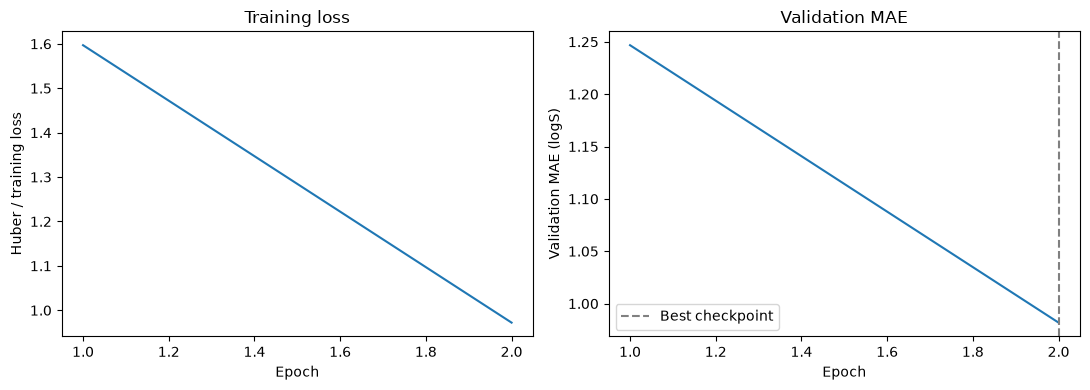

,seed,best_epoch,train_MAE,valid_MAE,MAE_generalization_gap
0,0,2,1.314,0.9818,-0.3322


In [27]:
seed_to_plot = SEEDS[0]
history = histories[seed_to_plot]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history["epoch"], history["train_loss"])
axes[0].set(xlabel="Epoch", ylabel="Huber / training loss", title="Training loss")

axes[1].plot(history["epoch"], history["valid_MAE"])
axes[1].axvline(
    results_df.loc[results_df["seed"] == seed_to_plot, "best_epoch"].iloc[0],
    linestyle="--", color="gray", label="Best checkpoint",
)
axes[1].set(xlabel="Epoch", ylabel="Validation MAE (logS)", title="Validation MAE")
axes[1].legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / f"learning_curves_seed_{seed_to_plot}.png", dpi=160)
plt.show()

results_df["MAE_generalization_gap"] = results_df["valid_MAE"] - results_df["train_MAE"]
display(results_df[["seed", "best_epoch", "train_MAE", "valid_MAE", "MAE_generalization_gap"]].round(4))

## 10. Verify checkpoint restoration

We save the **normalizer together with the model**, because their parameters are both necessary for inference. Loading the weights without applying the same training-fitted normalizer would produce inconsistent input features.

In [28]:
saved = torch.load(checkpoints[SEEDS[0]], map_location="cpu", weights_only=False)

restored_model = MolecularGNN(config)
restored_model.load_state_dict(saved["model_state_dict"])
restored_model.eval()

restored_normalizer = GraphFeatureNormalizer.from_config(config)
restored_normalizer.load_state_dict(saved["normalizer_state_dict"])

assert restored_normalizer.is_fitted
assert saved["feature_schema"] == feature_schema
print("Checkpoint restored:", checkpoints[SEEDS[0]].name)
print("Best epoch:", saved["best_epoch"])
print("Saved validation MAE:", saved["best_valid_MAE"])
print("Normalizer restored:", restored_normalizer.is_fitted)

Checkpoint restored: gine_seed_0.pt
Best epoch: 2
Saved validation MAE: 0.9818309545516968
Normalizer restored: True


## Conclusions and next steps

At the end of a **full** run, we have:

- `models/gnn/full/gine_seed_<seed>.pt`: best GINE model **and** seed-specific graph normalizer;
- `results/gnn/full/history_seed_<seed>.csv`: training history;
- `results/gnn/full/valid_predictions_seed_<seed>.csv`: aligned molecule-level validation predictions;
- `results/gnn/full/training_results.csv`: train/validation MAE, RMSE, R², best epoch and elapsed time.

The `smoke/` directory contains analogous outputs from a **small, non-representative** technical run. Do not use those values in scientific comparisons.

**Next notebook — `10_gnn_evaluation.ipynb`:** compare the fully trained GNN with XGBoost over the same seeds, inspect solubility-range errors and molecule-level residuals, and evaluate on the official test set only after the architecture and hyperparameters have been selected from validation results.